# Comparacao dos cinco algoritmos com intervalos de confianca por bootstrap

Este notebook recalcula AUPRC, ROC-AUC e Brier Score dos cinco algoritmos ja treinados na fase de modelagem, usando as predicoes salvas para o teste de 2024.
Como o teste de 2024 tem apenas 208 obitos entre 3978 registros, qualquer estimativa pontual dessas metricas carrega incerteza relevante, que nao fica visivel numa unica tabela de valores pontuais.
Para quantificar essa incerteza, o notebook usa bootstrap, reamostrando o conjunto de teste com reposicao muitas vezes e recalculando as metricas em cada reamostragem, o que permite estimar um intervalo de confianca de 95 por cento para cada metrica de cada algoritmo.
Por fim, o notebook compara diretamente, por bootstrap pareado, os dois algoritmos com melhor AUPRC pontual, para avaliar se a diferenca entre eles e consistente ou se pode ser explicada por variacao amostral.

Importa as bibliotecas necessarias, inclui a raiz do projeto no caminho de importacao para reutilizar `utils/preprocessing.py`, e cria os diretorios de saida usados ao longo do notebook.
A tabela final de intervalos de confianca e salva em `analysis/results_avaliacao/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(PROJECT_ROOT))

from utils import preprocessing

DIRETORIO_METRICAS = PROJECT_ROOT / "output" / "metricas"
DIRETORIO_RESULTADOS_ANALISE = PROJECT_ROOT / "analysis" / "results_avaliacao"
DIRETORIO_RESULTADOS_ANALISE.mkdir(parents=True, exist_ok=True)

ALGORITMOS = ["regressao_logistica", "arvore_decisao", "random_forest", "xgboost", "lightgbm"]
NUMERO_REAMOSTRAGENS = 2000
SEMENTE_ALEATORIA = 42

Carrega, para cada um dos cinco algoritmos, as predicoes de probabilidade e o alvo real salvos pela fase de modelagem para o teste de 2024.
Confirma que o alvo real e identico entre os cinco arquivos, ja que todos vem do mesmo conjunto de teste, apenas com probabilidades preditas diferentes.

In [2]:
predicoes_teste2024 = {
    algoritmo: pd.read_parquet(DIRETORIO_METRICAS / f"{algoritmo}_predicoes_teste2024.parquet")
    for algoritmo in ALGORITMOS
}

alvo_real_teste2024 = predicoes_teste2024[ALGORITMOS[0]]["obito"].to_numpy()
for algoritmo in ALGORITMOS:
    assert np.array_equal(predicoes_teste2024[algoritmo]["obito"].to_numpy(), alvo_real_teste2024)

numero_registros_teste2024 = len(alvo_real_teste2024)
numero_registros_teste2024, alvo_real_teste2024.sum()

(3978, np.int64(208))

Recalcula AUPRC, ROC-AUC e Brier Score de cada algoritmo sobre o teste de 2024 completo, usando `avaliar_predicoes` de `utils/preprocessing.py`, como estimativa pontual de referencia para as secoes seguintes.

In [3]:
metricas_pontuais = []
for algoritmo in ALGORITMOS:
    probabilidade_predita = predicoes_teste2024[algoritmo]["probabilidade_predita"].to_numpy()
    metricas = preprocessing.avaliar_predicoes(alvo_real_teste2024, probabilidade_predita)
    metricas["algoritmo"] = algoritmo
    metricas_pontuais.append(metricas)

tabela_metricas_pontuais = pd.DataFrame(metricas_pontuais).set_index("algoritmo")
tabela_metricas_pontuais.sort_values("auprc", ascending=False)

,auprc,roc_auc,brier_score
algoritmo,,,
regressao_logistica,0.206604,0.810633,0.239320
xgboost,0.196245,0.765930,0.189623
random_forest,0.187008,0.804966,0.072640
lightgbm,0.168298,0.745586,0.140349
arvore_decisao,0.120433,0.714876,0.239224


Plota as curvas ROC e de precisao-revocacao dos cinco algoritmos sobrepostas, como complemento visual a tabela de metricas pontuais acima.
A curva ROC usa a diagonal como referencia de um classificador sem poder discriminativo, e a curva de precisao-revocacao usa a prevalencia de obito do teste de 2024 como referencia equivalente, ja que a precisao de um classificador aleatorio e constante e igual a prevalencia em qualquer nivel de revocacao.
As duas figuras sao salvas em `analysis/plots/avaliacao/`.

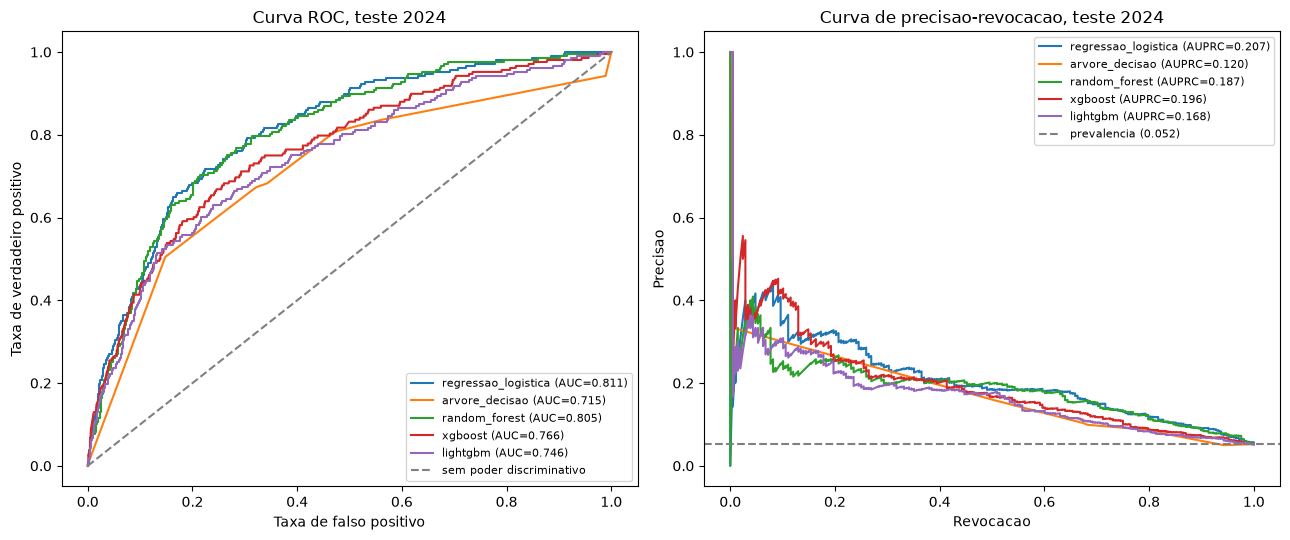

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve

DIRETORIO_PLOTS_AVALIACAO = PROJECT_ROOT / "analysis" / "plots" / "avaliacao"
DIRETORIO_PLOTS_AVALIACAO.mkdir(parents=True, exist_ok=True)

prevalencia_teste2024 = alvo_real_teste2024.mean()

figura, (eixo_roc, eixo_pr) = plt.subplots(1, 2, figsize=(13, 5.5))

for algoritmo in ALGORITMOS:
    probabilidade_predita = predicoes_teste2024[algoritmo]["probabilidade_predita"].to_numpy()

    taxa_falso_positivo, taxa_verdadeiro_positivo, _ = roc_curve(alvo_real_teste2024, probabilidade_predita)
    roc_auc_algoritmo = tabela_metricas_pontuais.loc[algoritmo, "roc_auc"]
    eixo_roc.plot(
        taxa_falso_positivo, taxa_verdadeiro_positivo,
        label=f"{algoritmo} (AUC={roc_auc_algoritmo:.3f})",
    )

    precisao, revocacao, _ = precision_recall_curve(alvo_real_teste2024, probabilidade_predita)
    auprc_algoritmo = tabela_metricas_pontuais.loc[algoritmo, "auprc"]
    eixo_pr.plot(
        revocacao, precisao,
        label=f"{algoritmo} (AUPRC={auprc_algoritmo:.3f})",
    )

eixo_roc.plot([0, 1], [0, 1], linestyle="--", color="gray", label="sem poder discriminativo")
eixo_roc.set_xlabel("Taxa de falso positivo")
eixo_roc.set_ylabel("Taxa de verdadeiro positivo")
eixo_roc.set_title("Curva ROC, teste 2024")
eixo_roc.legend(fontsize=8, loc="lower right")

eixo_pr.axhline(prevalencia_teste2024, linestyle="--", color="gray", label=f"prevalencia ({prevalencia_teste2024:.3f})")
eixo_pr.set_xlabel("Revocacao")
eixo_pr.set_ylabel("Precisao")
eixo_pr.set_title("Curva de precisao-revocacao, teste 2024")
eixo_pr.legend(fontsize=8, loc="upper right")

figura.tight_layout()
figura.savefig(DIRETORIO_PLOTS_AVALIACAO / "curvas_roc_precisao_revocacao_5_algoritmos.png", dpi=150)
plt.show()

Gera, uma unica vez, os indices de reamostragem com reposicao usados em todas as repeticoes de bootstrap.
Usar os mesmos indices de reamostragem para os cinco algoritmos garante que a comparacao pareada entre algoritmos, feita mais adiante, seja valida, ja que cada reamostragem representa o mesmo conjunto hipotetico de casos para todos os algoritmos.
Uma semente fixa garante que os resultados sejam reproduziveis entre execucoes do notebook.

In [5]:
gerador_aleatorio = np.random.default_rng(SEMENTE_ALEATORIA)

indices_reamostragem = gerador_aleatorio.integers(
    low=0, high=numero_registros_teste2024, size=(NUMERO_REAMOSTRAGENS, numero_registros_teste2024)
)

indices_reamostragem.shape

(2000, 3978)

Para cada algoritmo e cada reamostragem, recalcula AUPRC e ROC-AUC sobre a amostra reamostrada do teste de 2024.
Uma reamostragem que, por acaso, nao contenha nenhum obito e descartada dessa metrica especifica, ja que AUPRC e ROC-AUC nao sao definidos sem as duas classes presentes, o que e raro dado que o teste de 2024 tem 208 obitos, mas e tratado de forma explicita por seguranca.
O resultado e uma distribuicao bootstrap de AUPRC e de ROC-AUC para cada algoritmo, guardada em um dicionario indexado pelo nome do algoritmo.

In [6]:
from sklearn.metrics import average_precision_score, roc_auc_score

distribuicao_bootstrap_auprc = {}
distribuicao_bootstrap_roc_auc = {}

for algoritmo in ALGORITMOS:
    probabilidade_predita = predicoes_teste2024[algoritmo]["probabilidade_predita"].to_numpy()

    valores_auprc = []
    valores_roc_auc = []
    for linha_indices in indices_reamostragem:
        alvo_reamostrado = alvo_real_teste2024[linha_indices]
        probabilidade_reamostrada = probabilidade_predita[linha_indices]
        if alvo_reamostrado.sum() == 0 or alvo_reamostrado.sum() == len(alvo_reamostrado):
            continue
        valores_auprc.append(average_precision_score(alvo_reamostrado, probabilidade_reamostrada))
        valores_roc_auc.append(roc_auc_score(alvo_reamostrado, probabilidade_reamostrada))

    distribuicao_bootstrap_auprc[algoritmo] = np.array(valores_auprc)
    distribuicao_bootstrap_roc_auc[algoritmo] = np.array(valores_roc_auc)

{algoritmo: len(distribuicao_bootstrap_auprc[algoritmo]) for algoritmo in ALGORITMOS}

{'regressao_logistica': 2000,
 'arvore_decisao': 2000,
 'random_forest': 2000,
 'xgboost': 2000,
 'lightgbm': 2000}

Constroi a tabela final de intervalos de confianca de 95 por cento para AUPRC e ROC-AUC de cada algoritmo, usando os percentis 2,5 e 97,5 das respectivas distribuicoes bootstrap.
A estimativa pontual reportada e a calculada sobre o teste de 2024 completo, e nao a media da distribuicao bootstrap, para manter coerencia com a tabela comparativa produzida na fase de modelagem.

In [7]:
linhas_intervalo_confianca = []
for algoritmo in ALGORITMOS:
    for nome_metrica, distribuicao_bootstrap in [
        ("auprc", distribuicao_bootstrap_auprc[algoritmo]),
        ("roc_auc", distribuicao_bootstrap_roc_auc[algoritmo]),
    ]:
        linhas_intervalo_confianca.append(
            {
                "algoritmo": algoritmo,
                "metrica": nome_metrica,
                "estimativa_pontual": tabela_metricas_pontuais.loc[algoritmo, nome_metrica],
                "limite_inferior_ic95": np.percentile(distribuicao_bootstrap, 2.5),
                "limite_superior_ic95": np.percentile(distribuicao_bootstrap, 97.5),
            }
        )

tabela_intervalo_confianca = pd.DataFrame(linhas_intervalo_confianca)
tabela_intervalo_confianca.sort_values(["metrica", "estimativa_pontual"], ascending=[True, False])

,algoritmo,metrica,estimativa_pontual,limite_inferior_ic95,limite_superior_ic95
0,regressao_logistica,auprc,0.206604,0.165705,0.259545
6,xgboost,auprc,0.196245,0.153694,0.252487
4,random_forest,auprc,0.187008,0.152767,0.237473
8,lightgbm,auprc,0.168298,0.132393,0.217637
2,arvore_decisao,auprc,0.120433,0.100434,0.143894
1,regressao_logistica,roc_auc,0.810633,0.781412,0.837873
5,random_forest,roc_auc,0.804966,0.775827,0.832203
7,xgboost,roc_auc,0.765930,0.730732,0.800047
9,lightgbm,roc_auc,0.745586,0.708815,0.779820
3,arvore_decisao,roc_auc,0.714876,0.676716,0.751245


Identifica os dois algoritmos com maior AUPRC pontual no teste de 2024, para a comparacao pareada por bootstrap feita a seguir.

In [8]:
ranking_auprc = tabela_metricas_pontuais["auprc"].sort_values(ascending=False)
melhor_algoritmo, segundo_melhor_algoritmo = ranking_auprc.index[0], ranking_auprc.index[1]

melhor_algoritmo, segundo_melhor_algoritmo

('regressao_logistica', 'xgboost')

Para cada uma das mesmas reamostragens usadas acima, calcula a diferenca de AUPRC entre o melhor e o segundo melhor algoritmo.
Usar a mesma reamostragem para os dois algoritmos, em vez de reamostrar cada um de forma independente, e o que torna essa comparacao pareada, e reduz a variancia da diferenca estimada em relacao a comparar as duas distribuicoes bootstrap de forma nao pareada.
Reamostragens sem nenhum obito ou sem nenhum sobrevivente sao descartadas, pela mesma razao da secao anterior.

In [9]:
probabilidade_melhor = predicoes_teste2024[melhor_algoritmo]["probabilidade_predita"].to_numpy()
probabilidade_segundo_melhor = predicoes_teste2024[segundo_melhor_algoritmo]["probabilidade_predita"].to_numpy()

diferencas_auprc_pareadas = []
for linha_indices in indices_reamostragem:
    alvo_reamostrado = alvo_real_teste2024[linha_indices]
    if alvo_reamostrado.sum() == 0 or alvo_reamostrado.sum() == len(alvo_reamostrado):
        continue
    auprc_melhor = average_precision_score(alvo_reamostrado, probabilidade_melhor[linha_indices])
    auprc_segundo_melhor = average_precision_score(alvo_reamostrado, probabilidade_segundo_melhor[linha_indices])
    diferencas_auprc_pareadas.append(auprc_melhor - auprc_segundo_melhor)

diferencas_auprc_pareadas = np.array(diferencas_auprc_pareadas)

diferenca_pontual_auprc = (
    tabela_metricas_pontuais.loc[melhor_algoritmo, "auprc"]
    - tabela_metricas_pontuais.loc[segundo_melhor_algoritmo, "auprc"]
)
fracao_reamostragens_com_diferenca_positiva = (diferencas_auprc_pareadas > 0).mean()

linha_comparacao_pareada = {
    "algoritmo": f"{melhor_algoritmo}_menos_{segundo_melhor_algoritmo}",
    "metrica": "diferenca_auprc",
    "estimativa_pontual": diferenca_pontual_auprc,
    "limite_inferior_ic95": np.percentile(diferencas_auprc_pareadas, 2.5),
    "limite_superior_ic95": np.percentile(diferencas_auprc_pareadas, 97.5),
}

linha_comparacao_pareada, fracao_reamostragens_com_diferenca_positiva

({'algoritmo': 'regressao_logistica_menos_xgboost',
  'metrica': 'diferenca_auprc',
  'estimativa_pontual': np.float64(0.010359282554846833),
  'limite_inferior_ic95': np.float64(-0.029090777226780204),
  'limite_superior_ic95': np.float64(0.04931051036988958)},
 np.float64(0.701))

Reune os intervalos de confianca por algoritmo e a comparacao pareada numa unica tabela final, e salva o resultado em `analysis/results_avaliacao/comparacao_bootstrap_teste2024.csv`.
A fracao de reamostragens com diferenca positiva entre os dois melhores algoritmos e registrada como coluna adicional, apenas na linha da comparacao pareada, como uma leitura direta da forca da evidencia a favor do melhor algoritmo.

In [10]:
tabela_intervalo_confianca["fracao_reamostragens_diferenca_positiva"] = np.nan
linha_comparacao_pareada["fracao_reamostragens_diferenca_positiva"] = fracao_reamostragens_com_diferenca_positiva

tabela_final_bootstrap = pd.concat(
    [tabela_intervalo_confianca, pd.DataFrame([linha_comparacao_pareada])], ignore_index=True
)

tabela_final_bootstrap.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "comparacao_bootstrap_teste2024.csv", index=False
)
tabela_final_bootstrap

,algoritmo,metrica,estimativa_pontual,limite_inferior_ic95,limite_superior_ic95,fracao_reamostragens_diferenca_positiva
0,regressao_logistica,auprc,0.206604,0.165705,0.259545,NaN
1,regressao_logistica,roc_auc,0.810633,0.781412,0.837873,NaN
2,arvore_decisao,auprc,0.120433,0.100434,0.143894,NaN
3,arvore_decisao,roc_auc,0.714876,0.676716,0.751245,NaN
4,random_forest,auprc,0.187008,0.152767,0.237473,NaN
5,random_forest,roc_auc,0.804966,0.775827,0.832203,NaN
6,xgboost,auprc,0.196245,0.153694,0.252487,NaN
7,xgboost,roc_auc,0.765930,0.730732,0.800047,NaN
8,lightgbm,auprc,0.168298,0.132393,0.217637,NaN
9,lightgbm,roc_auc,0.745586,0.708815,0.779820,NaN


## Sintese dos achados

Os intervalos de confianca de 95 por cento de AUPRC se sobrepoem entre a maioria dos cinco algoritmos, o que reflete diretamente o numero reduzido de obitos no teste de 2024, apenas 208 entre 3978 registros.
Regressao Logistica, XGBoost, Random Forest e LightGBM formam um grupo com intervalos de AUPRC mutuamente sobrepostos, de 0,166 a 0,260, de 0,154 a 0,252, de 0,153 a 0,237 e de 0,132 a 0,218 respectivamente.
Arvore de Decisao tem o intervalo de AUPRC mais baixo dos cinco, de 0,100 a 0,144, sem sobreposicao com os intervalos de Regressao Logistica, XGBoost ou Random Forest, e com sobreposicao apenas parcial, concentrada na extremidade inferior, com o intervalo do LightGBM.
Pelo ROC-AUC, Regressao Logistica e Random Forest formam um par com intervalos praticamente coincidentes e os mais altos entre os cinco algoritmos, de 0,781 a 0,838 e de 0,776 a 0,832 respectivamente.
XGBoost, de 0,731 a 0,800, tem o limite superior do intervalo sobreposto a extremidade inferior desse par, e o limite inferior sobreposto ao intervalo do LightGBM, de 0,709 a 0,780, ocupando uma posicao intermediaria entre os dois grupos.
Arvore de Decisao volta a ter o intervalo de ROC-AUC mais baixo dos cinco algoritmos, de 0,677 a 0,751, com sobreposicao substancial com o intervalo do LightGBM e mais limitada com a extremidade inferior do intervalo do XGBoost, sem qualquer sobreposicao com os intervalos de Random Forest ou Regressao Logistica.
A comparacao pareada por bootstrap entre Regressao Logistica e XGBoost, os dois algoritmos com maior AUPRC pontual, mostra uma diferenca pontual de 0,0104 a favor da Regressao Logistica, com intervalo de confianca de 95 por cento entre -0,029 e 0,049, que inclui o zero, e a diferenca e positiva em 70,1 por cento das reamostragens, uma proporcao acima dos 50 por cento esperados sob ausencia de qualquer vantagem real, mas distante do limiar convencional de significancia estatistica de 95 por cento.
Essa leitura sugere apenas uma tendencia fraca a favor da Regressao Logistica sobre o XGBoost em AUPRC, e a escolha entre os algoritmos do grupo superior, que inclui tambem Random Forest e LightGBM, deve continuar se apoiando em outros criterios, como a calibracao das probabilidades e a estabilidade entre 2024 e 2025, avaliados nos dois notebooks seguintes desta fase.
Arvore de Decisao e o unico dos cinco algoritmos cujo desempenho inferior e suficientemente consistente nas duas metricas para ser descartado com razoavel seguranca, enquanto a diferenca entre os quatro algoritmos restantes permanece incerta dado o grau de sobreposicao dos intervalos.